# Economic replay of fixed opportunity rankings

This second layer asks whether the first layer's event rankings translate into simulated profit. Models, labels, scores and candidate rules are held fixed. The primary scenario is **100ms arrival, uncapped capital and size, no imposed random failure probability**. Compare 0, 50, 250 and 500ms arrival, keeping the one-second unwind/hold constant.

Zero-delay execution is an optimistic displayed-book reference, not a theoretical upper bound or evidence of live fills. Final-test data remain closed. See [the economic report](../docs/reports/opportunity_economic_replay.md) and [simulator assumptions](../docs/simulator.md).

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from src.paths import PROCESSED_DIR
from src.simulator.opportunities import replay
from src.reporting.opportunity_replay import build_report, verify, verify_analysis, LABELS

MODELS = ROOT / 'results/opportunity_value'
OCCURRENCE = ROOT / 'results/opportunities'
DATA = PROCESSED_DIR / 'opportunity_value'
OBSERVATION_DATA = PROCESSED_DIR / 'opportunities'
RUN = ROOT / 'results/opportunity_replay'
RUN_REPLAY = False  # Set RUN to a new directory before enabling.
REBUILD_REPORT = False
if RUN_REPLAY:
    replay(RUN, MODELS, OCCURRENCE, DATA, OBSERVATION_DATA)
if REBUILD_REPORT:
    build_report(RUN, MODELS)
design = verify(RUN, MODELS)
verify_analysis(RUN)
print('Verified fixed predictions, persistent replay, source hashes and closed final test.')

Verified fixed predictions, persistent replay, source hashes and closed final test.


## Protocol

Six policies: quoted-gap, book logistic, book forest, forest with metadata, tuned two-stage forest and tuned value ensemble. References: monitor-all and 20 fixed-seed random policies. Each has an independent liquidity ledger, preserved across all hours and chronological folds. Event exclusion removes December Fed before ranking and reallocates its monitoring slots. Random scores are paired across budgets, scopes and latencies.

Per-leg fill-or-kill orders use size and limits fixed at observation. Partial baskets unwind one second after arrival. The scheduler submits at an eligible gap's start (including a selected window's initial state), without requiring the gap to persist until arrival. It makes no retries within an uninterrupted episode, permits one attempt in flight per event and blocks unchanged/shared quoted liquidity across pairs and hours. The fixed hold also applies after successful or empty fills.

No future coverage labels filter selections. Unknown arrival or unwind states produce unknown P&L; the tables show their counts separately. Complete-basket margins use the guaranteed payout floor and are accounted at completion, not actual settlement cash receipt.

In [2]:
summary = pd.read_csv(RUN / 'analysis/comparison.csv')
headline = summary.loc[summary.fold.eq('all')]
fields = ['model', 'known_pnl_usd', 'completed_profit_usd', 'partial_pnl_usd',
          'attempts', 'completed', 'partial_attempts', 'unknown_attempts', 'max_drawdown_usd']
for budget in [5, 3]:
    print(f'100ms, top {budget}, all events')
    display(headline.loc[headline.scope.eq('all_events') & headline.top_n.eq(budget) &
                        headline.arrival_delay_s.eq(.1), fields]
            .sort_values('known_pnl_usd', ascending=False).round(2))
display(pd.read_csv(RUN / 'analysis/baseline_equivalence.csv'))

100ms, top 5, all events


,model,known_pnl_usd,completed_profit_usd,partial_pnl_usd,attempts,completed,partial_attempts,unknown_attempts,max_drawdown_usd
220,quoted_gap_rule,6045.25,6328.72,-283.47,491.0,474.00,17.00,0.0,142.08
240,tuned_value_ensemble,5963.27,6341.31,-378.05,497.0,480.00,17.00,0.0,205.91
200,monitor_all,5951.60,6366.35,-414.75,521.0,503.00,18.00,0.0,205.91
260,tuned_value_two_stage_random_forest,5946.19,6360.94,-414.75,505.0,487.00,18.00,0.0,205.96
180,fixed_combined_random_forest,5942.52,6357.27,-414.75,511.0,493.00,18.00,0.0,205.91
160,fixed_book_random_forest,5939.12,6353.86,-414.75,508.0,490.00,18.00,0.0,205.91
140,fixed_book_logistic,5903.33,6318.08,-414.75,483.0,465.00,18.00,0.0,206.15
588,random_mean,1747.61,1887.76,-140.16,188.7,181.75,6.95,0.0,97.42


100ms, top 3, all events


,model,known_pnl_usd,completed_profit_usd,partial_pnl_usd,attempts,completed,partial_attempts,unknown_attempts,max_drawdown_usd
0,fixed_book_logistic,5999.41,6282.37,-282.97,443.00,427.0,16.00,0.0,142.08
60,monitor_all,5951.60,6366.35,-414.75,521.00,503.0,18.00,0.0,205.91
40,fixed_combined_random_forest,5846.04,6260.02,-413.98,452.00,436.0,16.00,0.0,205.96
20,fixed_book_random_forest,5845.60,6260.09,-414.48,450.00,433.0,17.00,0.0,205.96
100,tuned_value_ensemble,4894.95,5137.32,-242.37,425.00,413.0,12.00,0.0,142.08
120,tuned_value_two_stage_random_forest,4635.97,4906.60,-270.63,424.00,410.0,14.00,0.0,142.08
80,quoted_gap_rule,4379.96,4498.12,-118.16,376.00,364.0,12.00,0.0,44.48
568,random_mean,961.75,1054.65,-92.91,116.45,112.4,4.05,0.0,72.02


,top_n,model,matched,reference_sha256
0,5,quoted_gap_rule,True,ab3f880f31fd53069ace8c7e0b417c845d3e553c1a401b...
1,5,monitor_all,True,ab3f880f31fd53069ace8c7e0b417c845d3e553c1a401b...
2,3,quoted_gap_rule,True,8e57b1f8b9de5b01f98d692257611130341c6c7dc330c0...
3,3,monitor_all,True,8e57b1f8b9de5b01f98d692257611130341c6c7dc330c0...


## Latency sensitivity

These panels show known simulated net P&L for every timing assumption. The random row is the mean of 20 actual independent replays, not a single tradable policy. Its seed spread is separate from statistical uncertainty about market generalisation. Lower latency need not improve every policy monotonically: changed fills and reservation histories can change later trades.

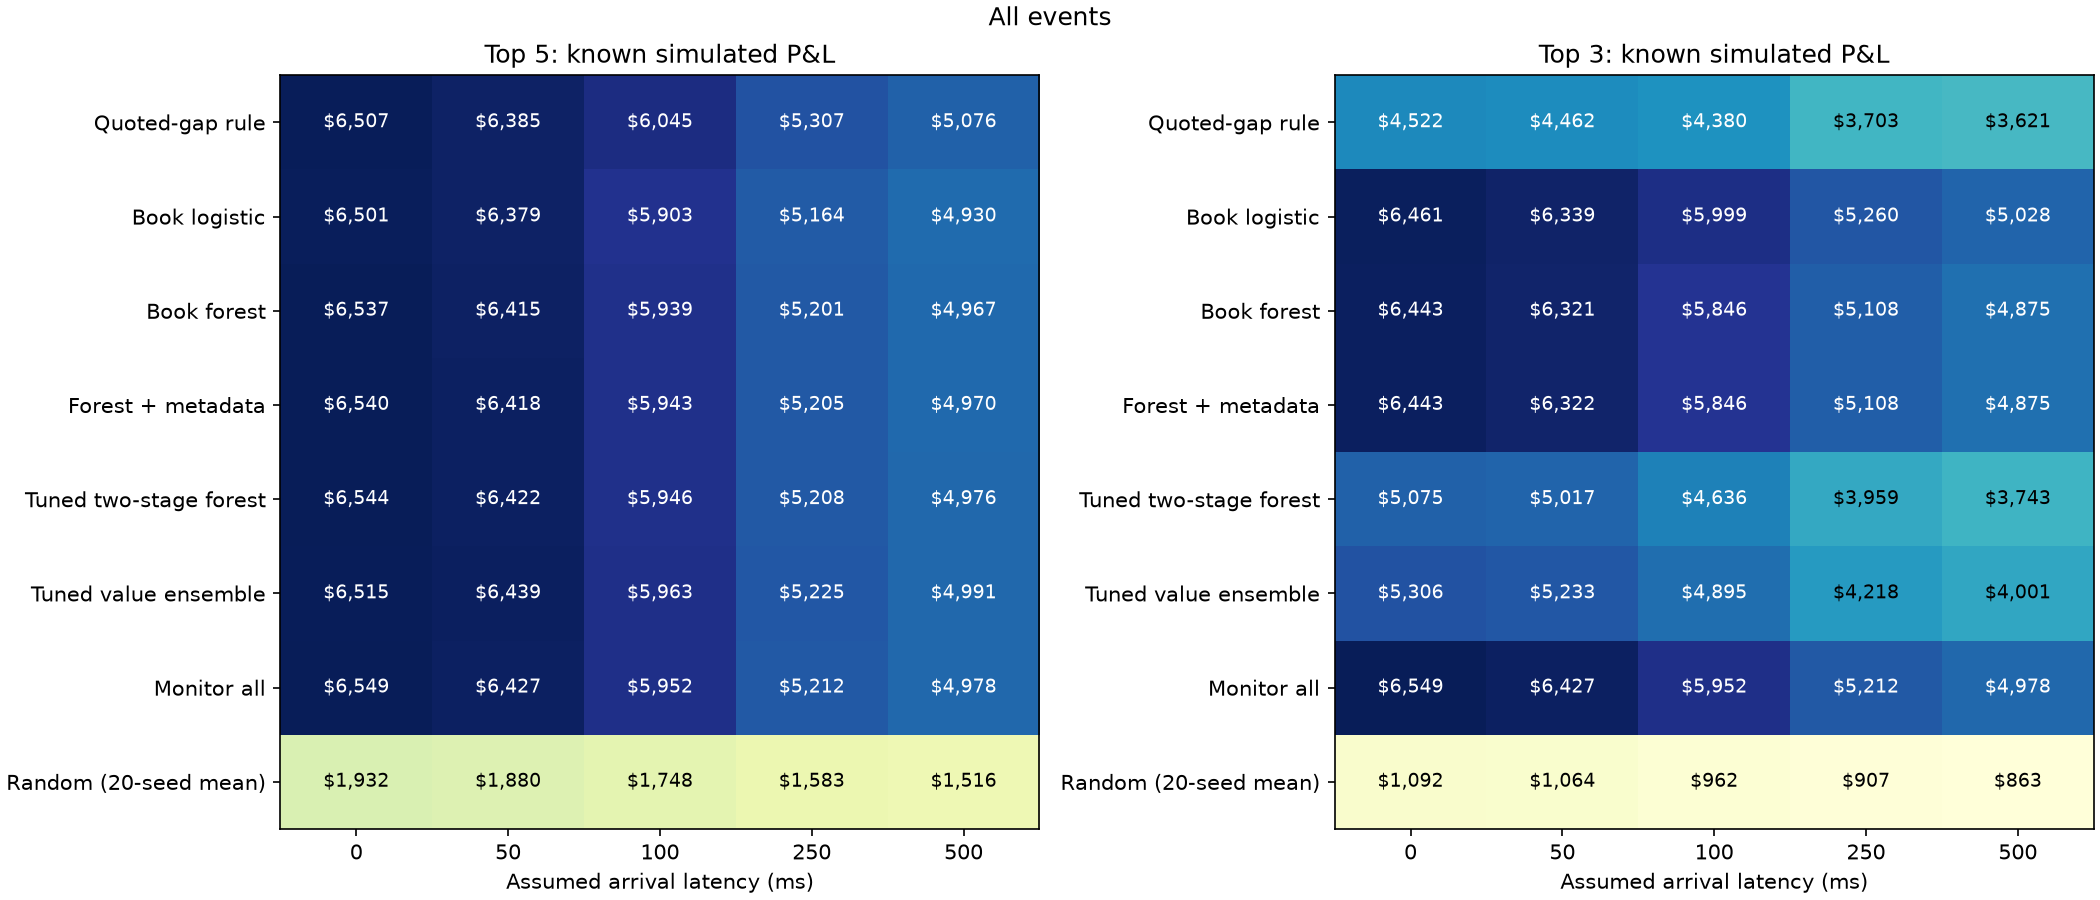

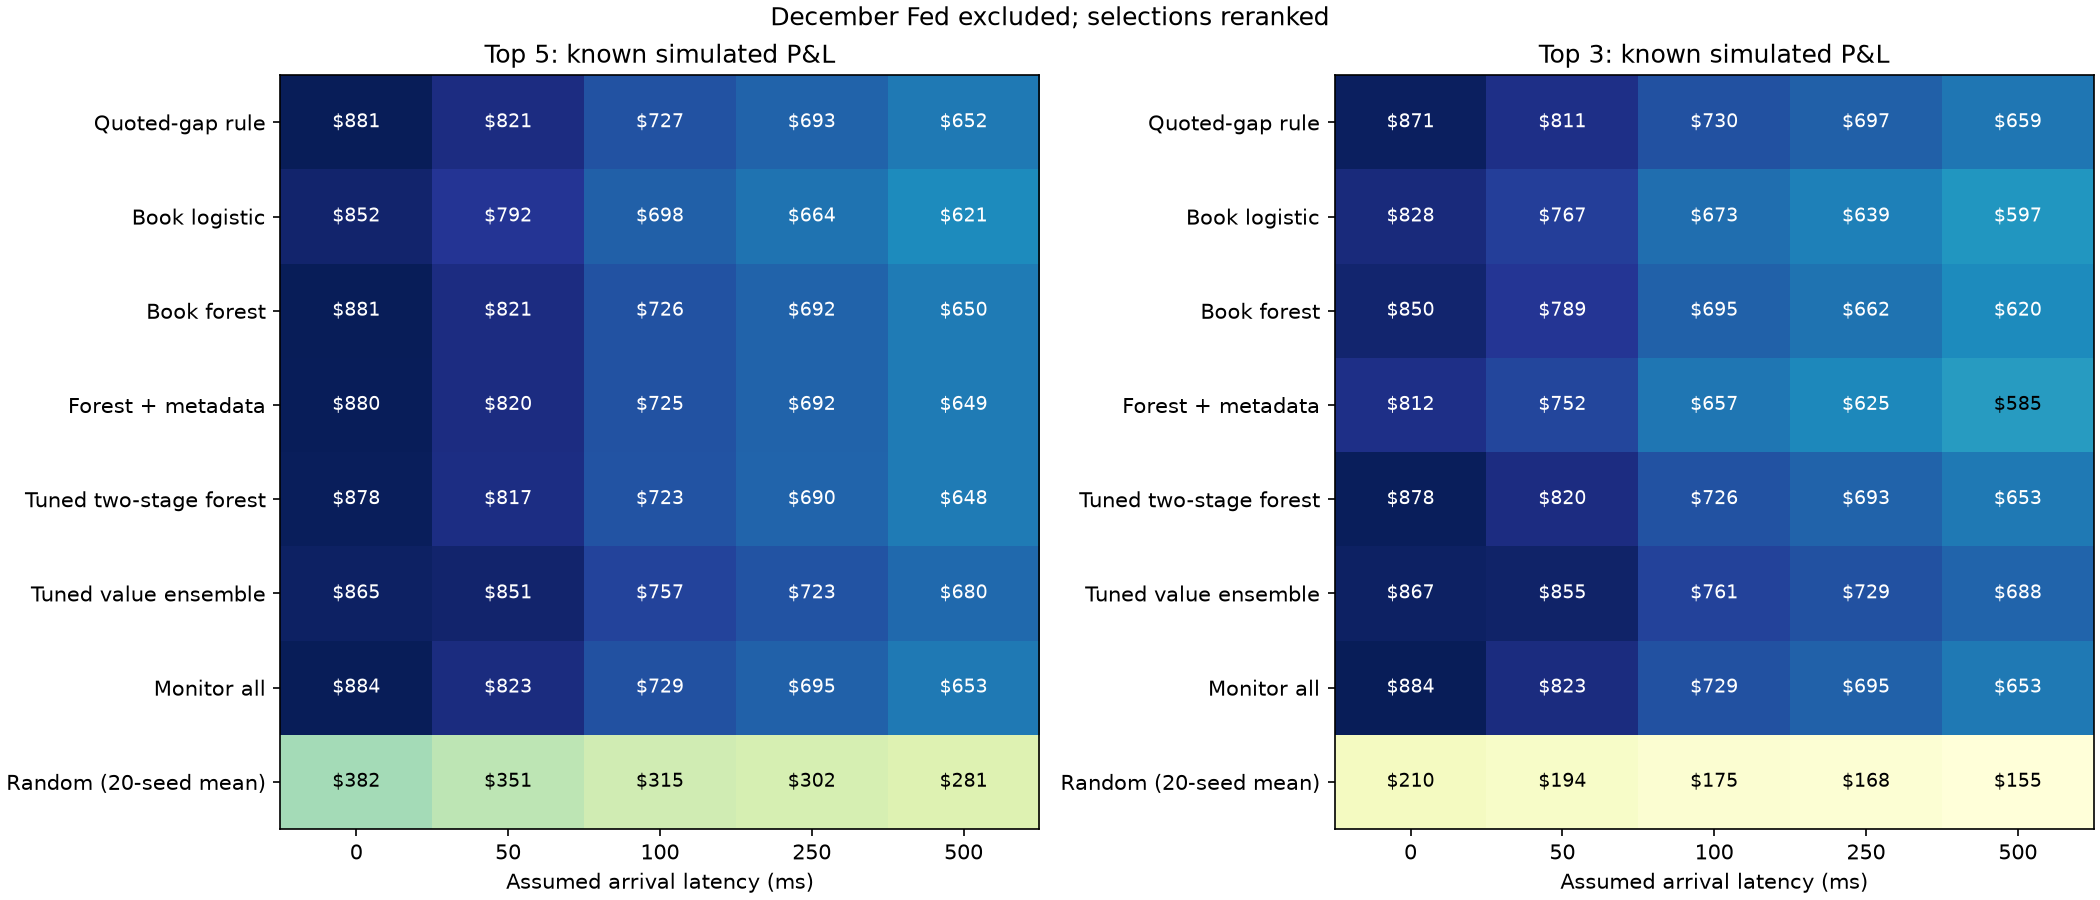

,scope,top_n,arrival_delay_s,fold,mean,std,min,max,seed_p025,seed_p975
8,all_events,3,0.1,all,961.75,243.55,418.20,1426.24,557.01,1369.29
28,all_events,5,0.1,all,1747.61,337.46,1134.78,2391.82,1164.27,2342.20
48,exclude_december_fed,3,0.1,all,174.61,108.66,2.12,489.53,29.14,409.11
68,exclude_december_fed,5,0.1,all,315.17,135.49,92.88,542.13,119.00,534.52


In [3]:
display(Image(filename=str(RUN / 'analysis/all_events_latency.png')))
display(Image(filename=str(RUN / 'analysis/exclude_december_fed_latency.png')))
random = pd.read_csv(RUN / 'analysis/random_seed_spread.csv')
display(random.loc[random.fold.eq('all') & random.arrival_delay_s.eq(.1)].round(2))

## P&L through time

Each policy has its own panel, with the quoted-gap curve in grey. Margins on completed baskets are booked at arrival; partial P&L is booked at unwind. Unknown outcomes are excluded, not treated as zero. These curves show contractual-margin accounting and are not a settled cash balance.

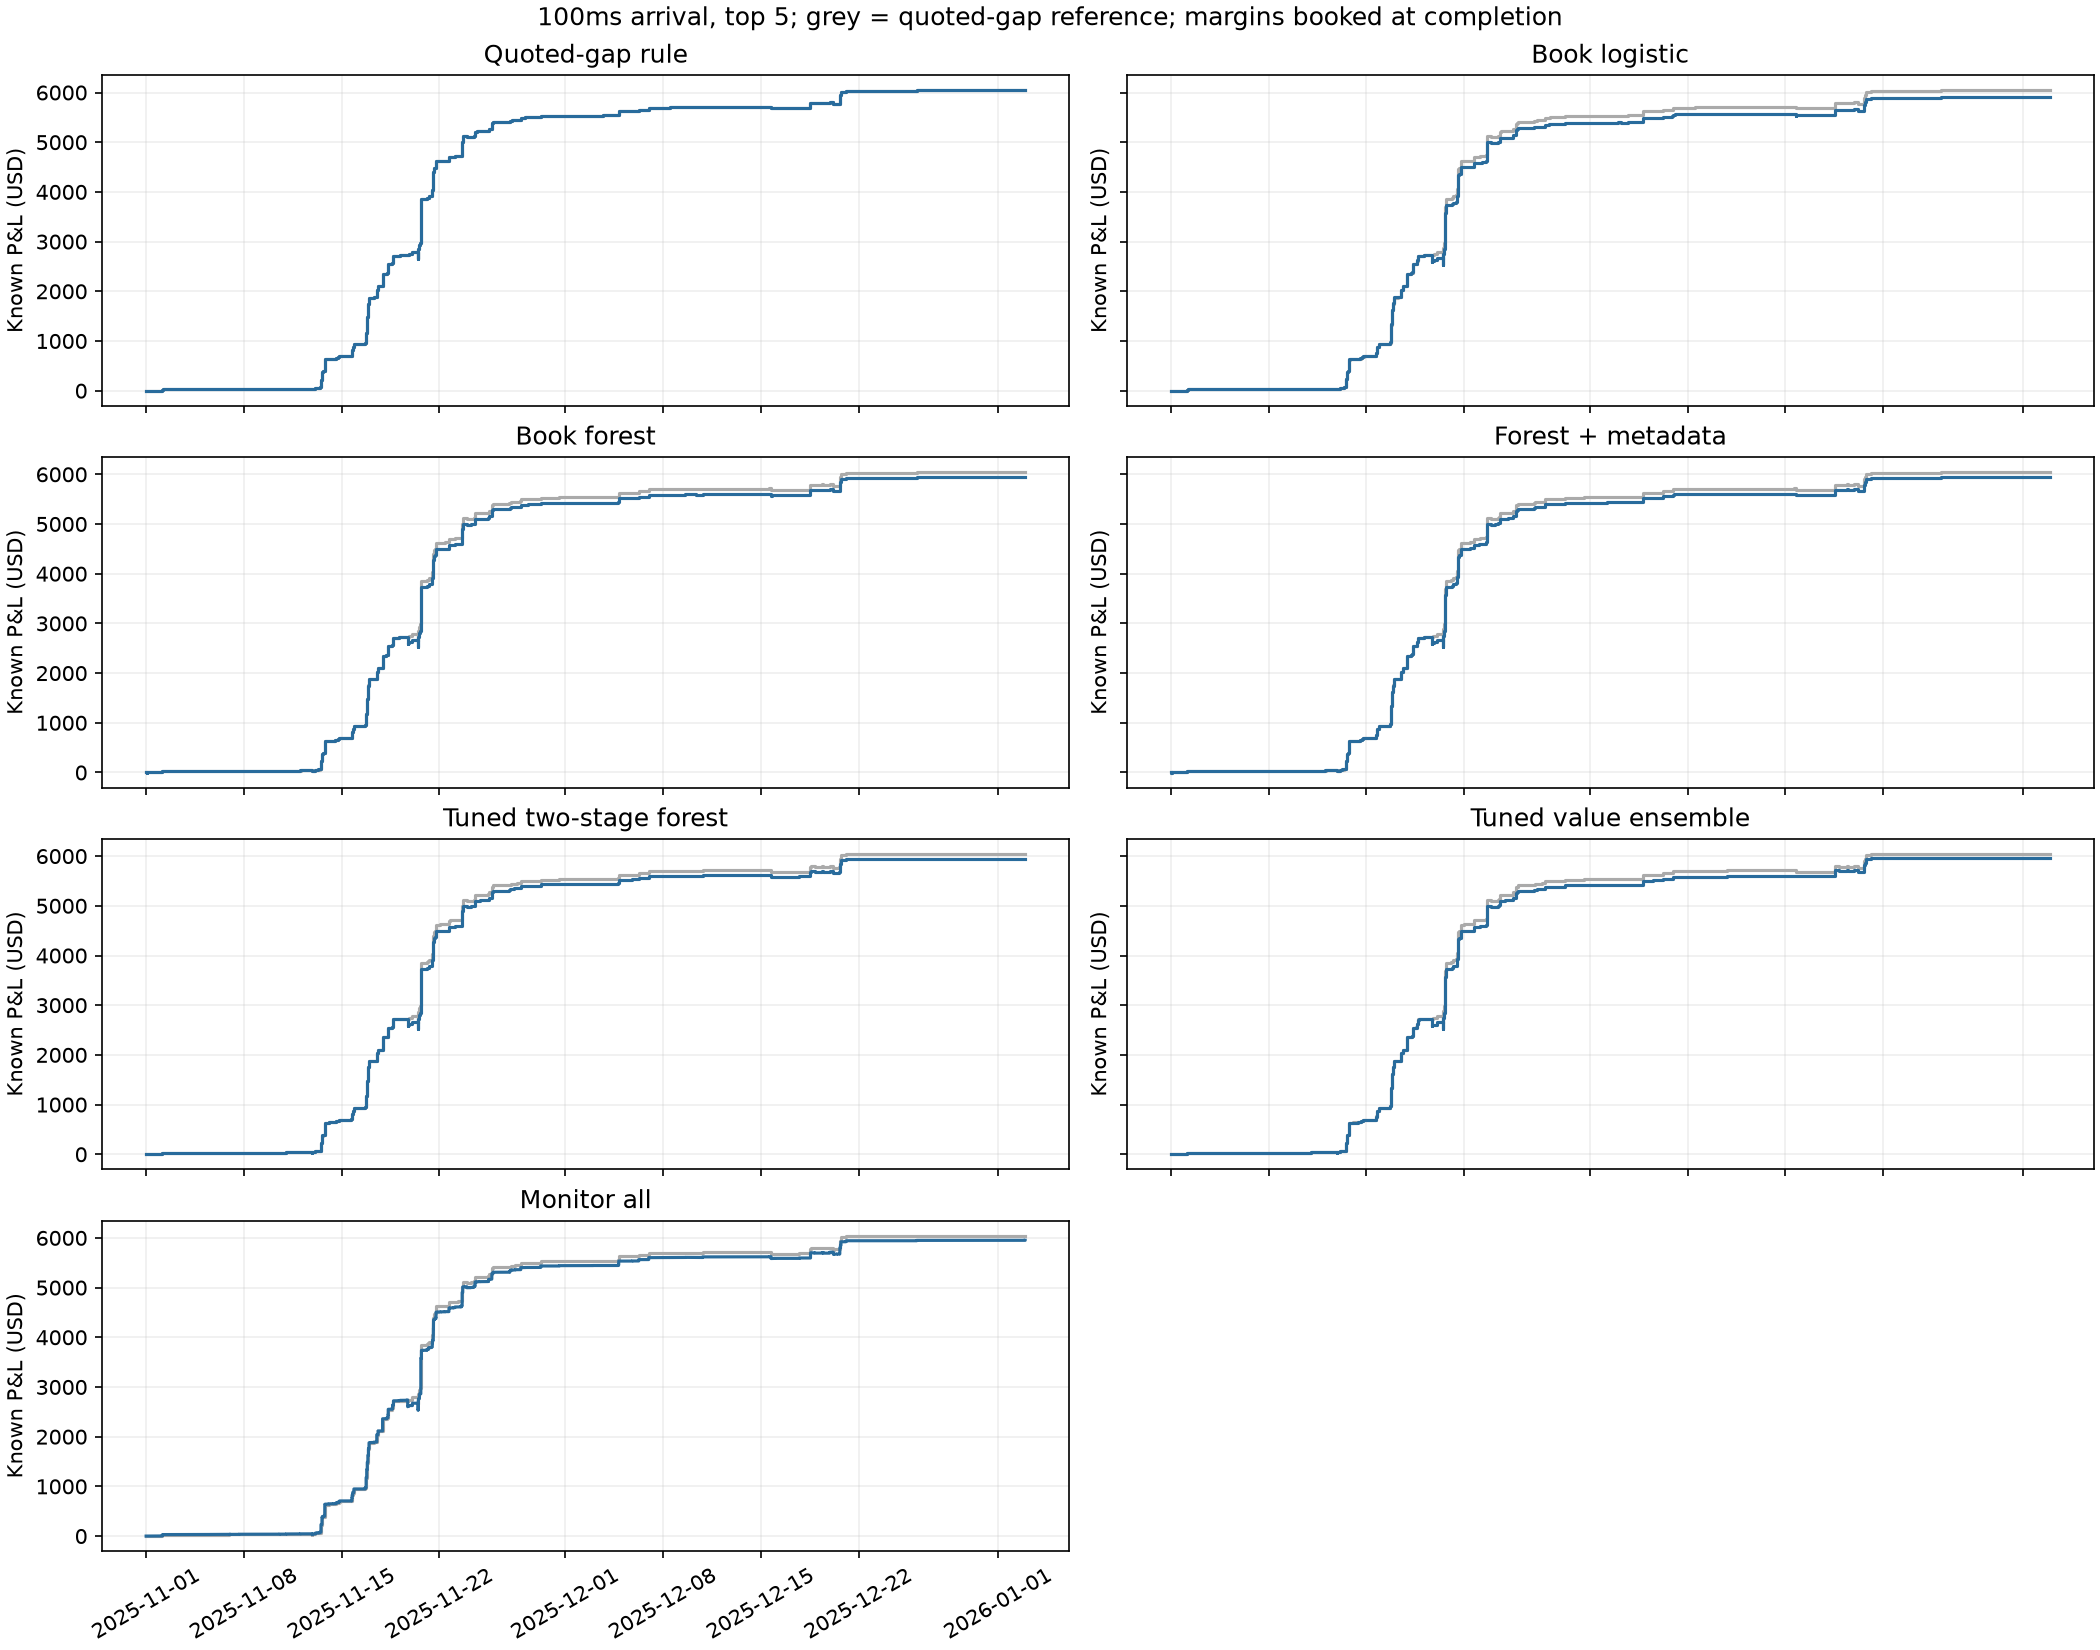

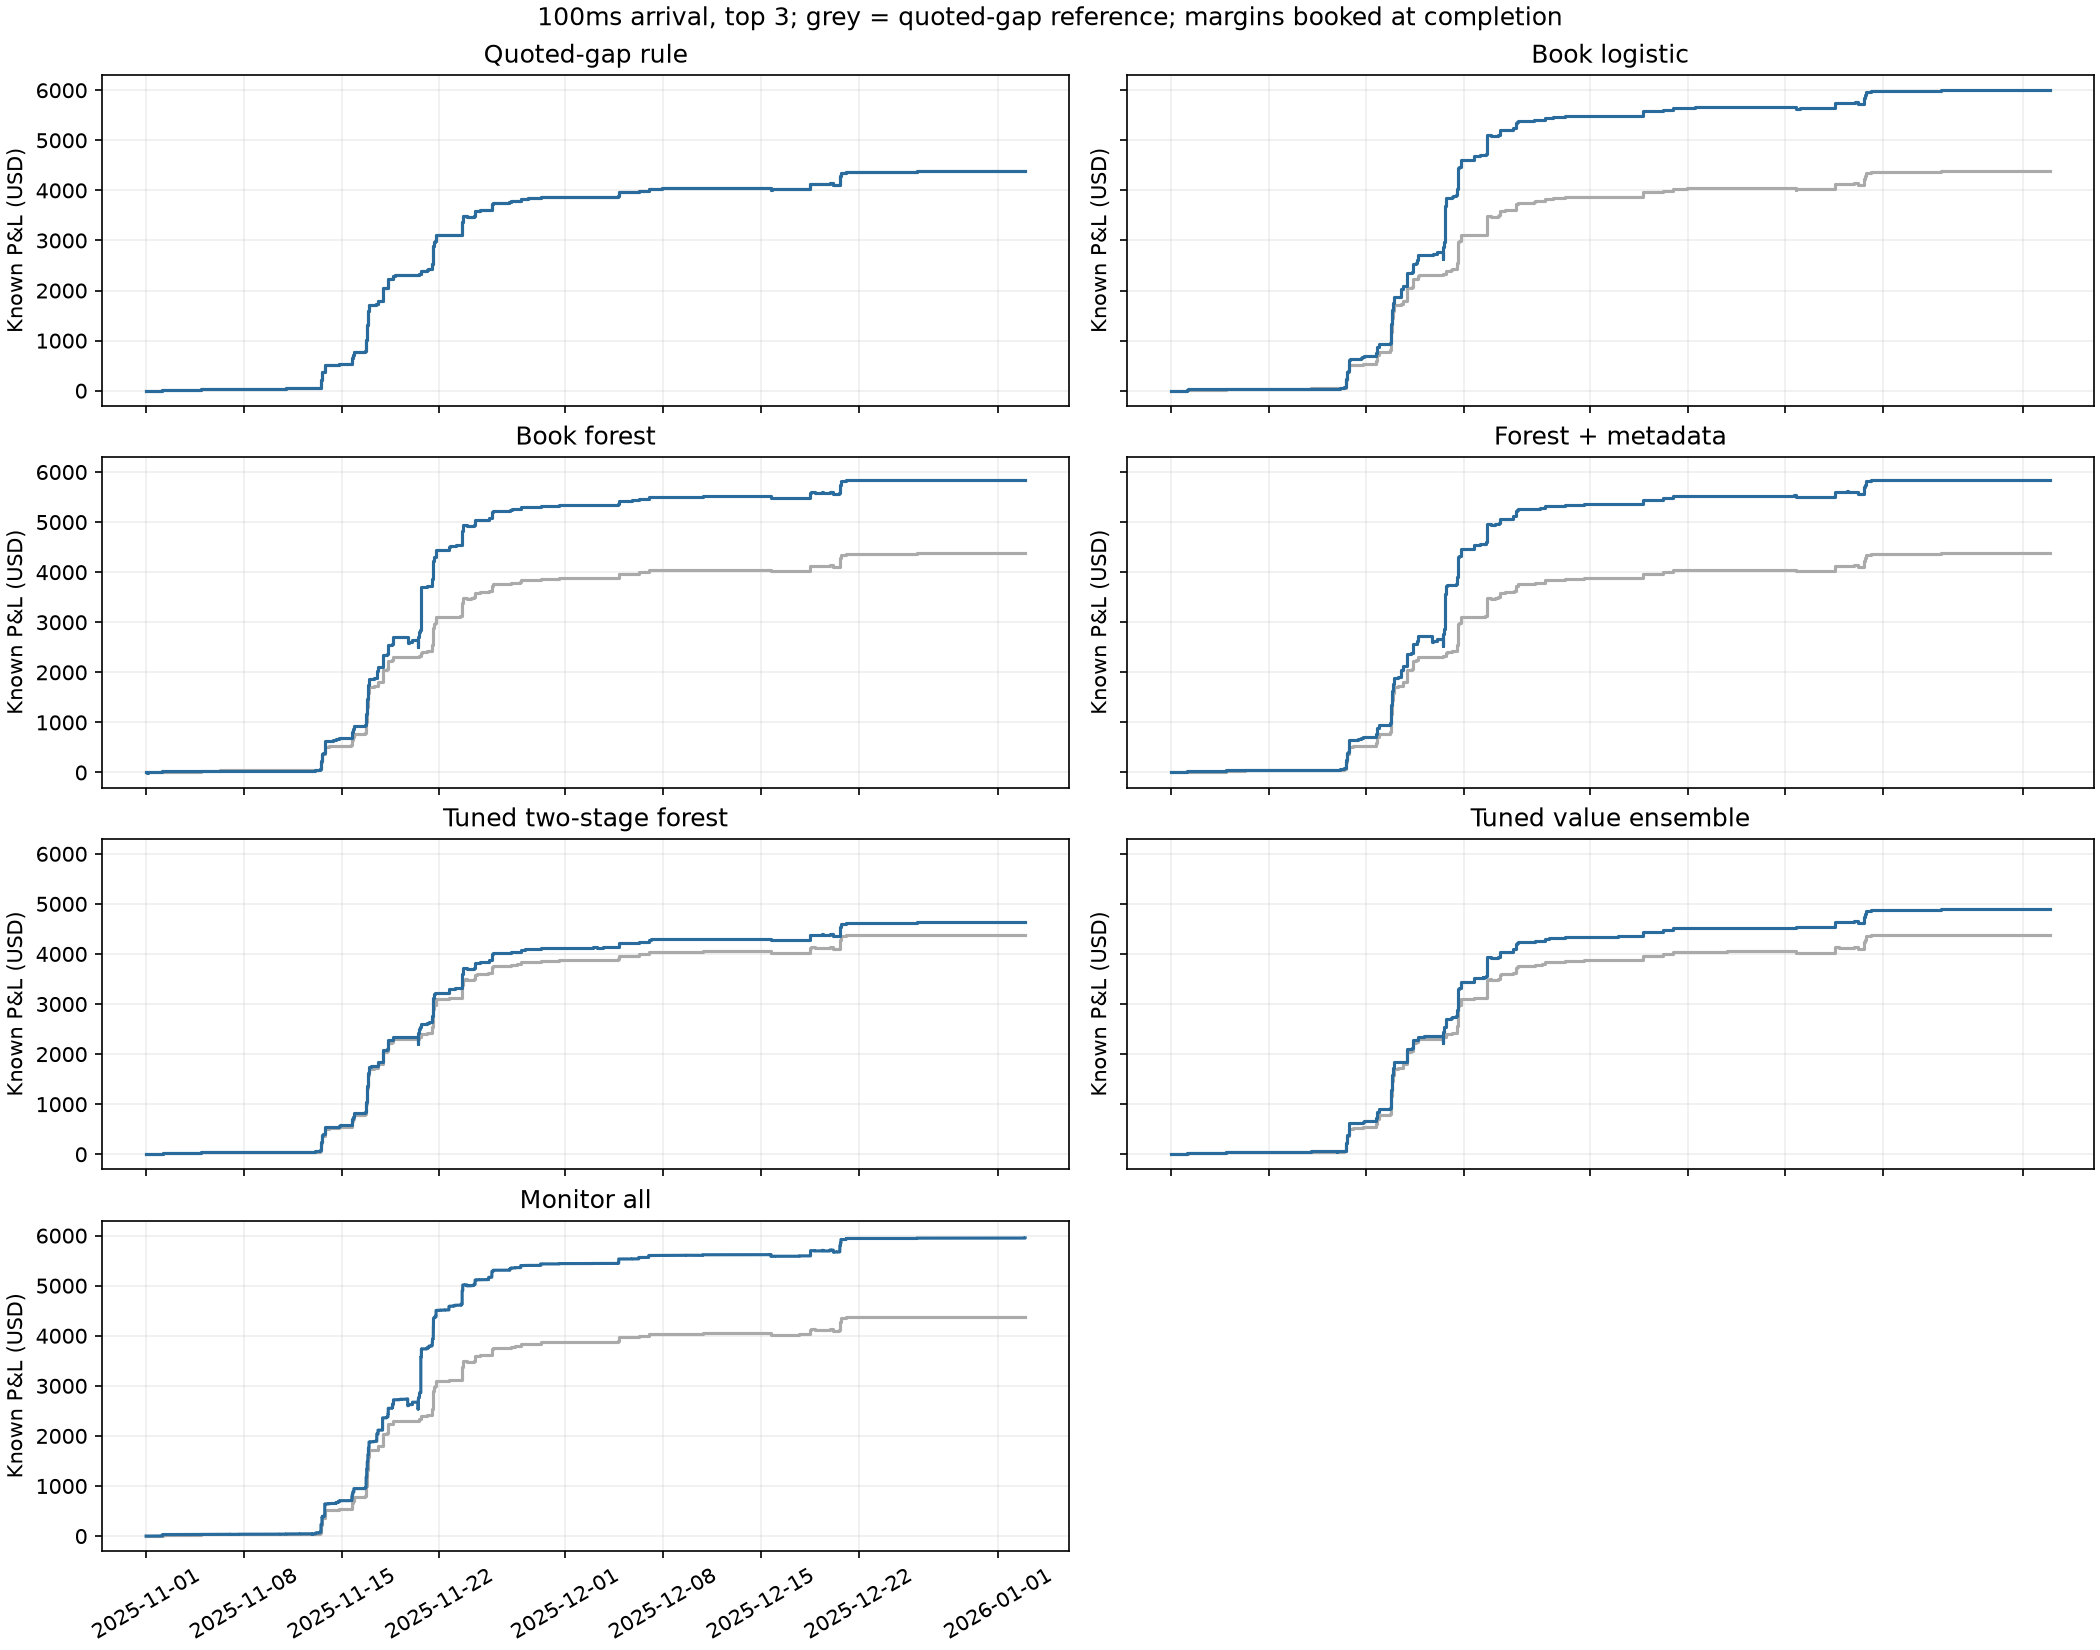

In [4]:
display(Image(filename=str(RUN / 'analysis/top5_pnl_panels.png')))
display(Image(filename=str(RUN / 'analysis/top3_pnl_panels.png')))

## Conversion and funding

Conversion is measured among **known positive event-hours selected**, not among all market opportunities. A positive selected hour can be skipped because the quoted liquidity was already reserved or another attempt was in flight.

`largest_reserved_cash_usd` is the largest single order's limit reservation. `peak_inflight_reservations_usd` aggregates temporary reservations across events, but excludes already acquired holdings. `no_settlement_funding_usd` is an explicit scenario: no completed baskets settle during the experiment; partial unwinds return known proceeds; unknown orders retain their reservation; unknown exits return no cash. Simultaneous submissions are funded before releases. It is not an estimated live capital requirement or an ROI denominator. Cumulative entry cash is turnover, not capital.

In [5]:
columns = ['model', 'top_n', 'known_positive_hours_selected', 'positive_hours_with_attempts',
           'positive_hours_with_completions', 'opportunity_hour_to_completion_rate',
           'selected_unknown_windows', 'unknown_attempts', 'largest_reserved_cash_usd',
           'peak_inflight_reservations_usd', 'no_settlement_funding_usd',
           'cumulative_purchase_cash_usd']
display(headline.loc[headline.scope.eq('all_events') & headline.arrival_delay_s.eq(.1), columns].round(3))
comparison = pd.read_csv(RUN / 'analysis/opportunity_vs_economics.csv')
display(comparison.loc[comparison.fold.eq('all') & comparison.scope.eq('all_events') &
                       comparison.arrival_delay_s.eq(.1),
                       ['model', 'top_n', 'recall', 'peak_value_recall', 'known_pnl_usd', 'partial_pnl_usd']].round(4))

,model,top_n,known_positive_hours_selected,positive_hours_with_attempts,positive_hours_with_completions,opportunity_hour_to_completion_rate,selected_unknown_windows,unknown_attempts,largest_reserved_cash_usd,peak_inflight_reservations_usd,no_settlement_funding_usd,cumulative_purchase_cash_usd
0,fixed_book_logistic,3,342.00,263.00,256.00,0.749,117.0,0.0,72920.866,72920.866,1411625.594,1419919.550
20,fixed_book_random_forest,3,339.00,259.00,251.00,0.740,496.0,0.0,72920.866,72920.866,1382599.397,1392566.098
40,fixed_combined_random_forest,3,334.00,254.00,247.00,0.740,644.0,0.0,72920.866,72920.866,1382653.963,1392612.264
60,monitor_all,3,385.00,288.00,279.00,0.725,3994.0,0.0,72920.866,72920.866,1452791.395,1462765.753
80,quoted_gap_rule,3,273.00,207.00,202.00,0.740,1316.0,0.0,52909.793,52909.793,1109836.041,1112281.368
100,tuned_value_ensemble,3,292.00,226.00,223.00,0.764,1081.0,0.0,52909.793,52909.793,1190945.054,1198289.284
120,tuned_value_two_stage_random_forest,3,301.00,232.00,225.00,0.748,1115.0,0.0,52909.793,52909.793,1168429.028,1176592.039
140,fixed_book_logistic,5,376.00,284.00,275.00,0.731,461.0,0.0,72920.866,72920.866,1419921.667,1429896.024
160,fixed_book_random_forest,5,367.00,278.00,269.00,0.733,1272.0,0.0,72920.866,72920.866,1448636.883,1458611.240
180,fixed_combined_random_forest,5,367.00,279.00,270.00,0.736,1439.0,0.0,72920.866,72920.866,1452040.476,1462014.833


,model,top_n,recall,peak_value_recall,known_pnl_usd,partial_pnl_usd
0,fixed_book_logistic,3,0.8883,0.9807,5999.4058,-282.9690
20,fixed_book_random_forest,3,0.8805,0.9845,5845.6033,-414.4822
40,fixed_combined_random_forest,3,0.8675,0.9776,5846.0373,-413.9822
60,monitor_all,3,NaN,NaN,5951.6045,-414.7462
80,quoted_gap_rule,3,0.7091,0.6008,4379.9587,-118.1639
100,tuned_value_ensemble,3,0.7584,0.7317,4894.9460,-242.3734
120,tuned_value_two_stage_random_forest,3,0.7818,0.7078,4635.9720,-270.6322
140,fixed_book_logistic,5,0.9766,0.9943,5903.3333,-414.7462
160,fixed_book_random_forest,5,0.9532,0.9986,5939.1168,-414.7462
180,fixed_combined_random_forest,5,0.9532,0.9987,5942.5238,-414.7462


## Stability and concentration

Fold summaries attribute trades to their initiating window, but do not reset reservations at fold boundaries. Fold funding scenarios start with that fold's included trades and do not estimate funding for inherited holdings; the full-period figure is the primary funding scenario.

Removing December Fed reranks the remaining events with the same fitted models. It is a concentration check, not unseen-topic validation. Paired intervals resample nine event families using actual policy returns. They are exploratory, exclude unknown P&L and do not adjust for trying multiple policies or execution scenarios.

In [6]:
focus = ['quoted_gap_rule', 'fixed_book_logistic', 'fixed_book_random_forest',
         'fixed_combined_random_forest', 'monitor_all']
display(summary.loc[summary.fold.ne('all') & summary.scope.eq('all_events') &
                    summary.arrival_delay_s.eq(.1) & summary.model.isin(focus),
                    ['fold', 'top_n'] + fields].round(2))
display(headline.loc[headline.scope.eq('exclude_december_fed') & headline.arrival_delay_s.eq(.1),
                    ['top_n'] + fields].round(2))
paired = pd.read_csv(RUN / 'analysis/paired_family_intervals.csv')
display(paired.loc[paired.arrival_delay_s.eq(.1) & paired.model.isin(focus)].round(2))
contributions = pd.read_csv(RUN / 'analysis/event_contributions.csv')
display(contributions.loc[contributions.scope.eq('all_events') & contributions.top_n.eq(5) &
                         contributions.arrival_delay_s.eq(.1) & contributions.model.eq('fixed_book_random_forest')]
        .sort_values('known_pnl_usd', ascending=False).head(12).round(2))

,fold,top_n,model,known_pnl_usd,completed_profit_usd,partial_pnl_usd,attempts,completed,partial_attempts,unknown_attempts,max_drawdown_usd
1,nov_early,3,fixed_book_logistic,4607.61,4766.31,-158.70,242.0,237.0,5.0,0.0,142.08
2,nov_late,3,fixed_book_logistic,1060.21,1084.14,-23.93,126.0,122.0,4.0,0.0,19.63
3,dec_late,3,fixed_book_logistic,331.58,431.92,-100.34,75.0,68.0,7.0,0.0,43.44
21,nov_early,3,fixed_book_random_forest,4442.86,4733.34,-290.48,245.0,238.0,7.0,0.0,205.96
22,nov_late,3,fixed_book_random_forest,1071.28,1095.21,-23.93,131.0,127.0,4.0,0.0,19.63
23,dec_late,3,fixed_book_random_forest,331.46,431.54,-100.08,74.0,68.0,6.0,0.0,43.44
41,nov_early,3,fixed_combined_random_forest,4463.49,4753.47,-289.98,243.0,237.0,6.0,0.0,205.96
42,nov_late,3,fixed_combined_random_forest,1067.52,1091.45,-23.93,140.0,136.0,4.0,0.0,19.63
43,dec_late,3,fixed_combined_random_forest,315.03,415.10,-100.08,69.0,63.0,6.0,0.0,49.89
61,nov_early,3,monitor_all,4508.55,4799.03,-290.48,284.0,277.0,7.0,0.0,205.91


,top_n,model,known_pnl_usd,completed_profit_usd,partial_pnl_usd,attempts,completed,partial_attempts,unknown_attempts,max_drawdown_usd
280,3,fixed_book_logistic,673.07,803.97,-130.90,257.00,242.00,15.00,0.0,43.44
300,3,fixed_book_random_forest,694.89,825.52,-130.63,278.00,264.00,14.00,0.0,43.44
320,3,fixed_combined_random_forest,657.43,788.07,-130.63,275.00,261.00,14.00,0.0,49.89
340,3,monitor_all,729.15,860.05,-130.90,315.00,300.00,15.00,0.0,43.44
360,3,quoted_gap_rule,729.50,847.67,-118.16,266.00,254.00,12.00,0.0,44.48
380,3,tuned_value_ensemble,761.09,852.45,-91.35,276.00,265.00,11.00,0.0,43.44
400,3,tuned_value_two_stage_random_forest,725.54,854.10,-128.55,279.00,266.00,13.00,0.0,43.44
420,5,fixed_book_logistic,697.69,828.59,-130.90,295.00,280.00,15.00,0.0,43.44
440,5,fixed_book_random_forest,726.35,857.25,-130.90,311.00,296.00,15.00,0.0,43.44
460,5,fixed_combined_random_forest,725.47,856.37,-130.90,311.00,296.00,15.00,0.0,43.44


,scope,top_n,arrival_delay_s,model,families,difference_usd,lower95,upper95
0,all_events,5,0.1,quoted_gap_rule,9,0.00,0.00,0.00
1,all_events,5,0.1,fixed_book_logistic,9,-141.92,-368.47,19.30
2,all_events,5,0.1,fixed_book_random_forest,9,-106.13,-342.44,26.21
3,all_events,5,0.1,fixed_combined_random_forest,9,-102.73,-339.66,29.54
6,all_events,5,0.1,monitor_all,9,-93.65,-318.23,35.28
35,all_events,3,0.1,quoted_gap_rule,9,0.00,0.00,0.00
36,all_events,3,0.1,fixed_book_logistic,9,1619.45,-164.03,5065.72
37,all_events,3,0.1,fixed_book_random_forest,9,1465.64,-161.90,4593.08
38,all_events,3,0.1,fixed_combined_random_forest,9,1466.08,-139.31,4590.66
41,all_events,3,0.1,monitor_all,9,1571.65,-50.16,4747.89


,scope,top_n,arrival_delay_s,model,event_slug,known_pnl_usd,attempts,unknown_attempts
2420,all_events,5,0.1,fixed_book_random_forest,fed-decision-in-december,5222.45,206,0
2421,all_events,5,0.1,fixed_book_random_forest,fed-decision-in-january,530.07,106,0
2423,all_events,5,0.1,fixed_book_random_forest,honduras-presidential-election,104.74,25,0
2427,all_events,5,0.1,fixed_book_random_forest,what-price-will-ethereum-hit-in-november-2025,54.60,41,0
2426,all_events,5,0.1,fixed_book_random_forest,what-price-will-bitcoin-hit-in-november-2025,36.42,26,0
2418,all_events,5,0.1,fixed_book_random_forest,avatar-fire-and-ash-opening-weekend-box-office,30.99,47,0
2424,all_events,5,0.1,fixed_book_random_forest,largest-company-end-of-november,5.57,9,0
2422,all_events,5,0.1,fixed_book_random_forest,gensyn-public-sale-total-commitments,4.35,6,0
2429,all_events,5,0.1,fixed_book_random_forest,which-party-holds-the-most-seats-after-argenti...,4.14,4,0
2430,all_events,5,0.1,fixed_book_random_forest,will-the-government-shutdown-end-by-763,1.61,11,0


## Interpretation

The replay measures outcomes conditional on recorded displayed depth, source-time alignment, complete capture and the declared policy. Actual information latency, competition, queue priority, market impact and settlement cash release are not measured. Faster assumed arrival does not establish that the data support subsecond live execution. No final model is chosen from the unopened test. Economic selection on these reused development periods remains exploratory.